In [1]:
import os

print(os.listdir("/kaggle/input"))

['competitions']


In [2]:
print(os.listdir("/kaggle/input/competitions"))

['hms-harmful-brain-activity-classification']


In [3]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(
    "/kaggle/input/competitions/hms-harmful-brain-activity-classification"
)
EEG_DIR = DATA_DIR / "train_eegs"

train = pd.read_csv(DATA_DIR / "train.csv")

print("Kích thước metadata:", train.shape)
print("Có thư mục EEG:", EEG_DIR.is_dir())

display(train.head())

Kích thước metadata: (106800, 15)
Có thư mục EEG: True


,eeg_id,eeg_sub_id,eeg_label_offset_seconds,spectrogram_id,spectrogram_sub_id,spectrogram_label_offset_seconds,label_id,patient_id,expert_consensus,seizure_vote,lpd_vote,gpd_vote,lrda_vote,grda_vote,other_vote
0,1628180742,0,0.0,353733,0,0.0,127492639,42516,Seizure,3,0,0,0,0,0
1,1628180742,1,6.0,353733,1,6.0,3887563113,42516,Seizure,3,0,0,0,0,0
2,1628180742,2,8.0,353733,2,8.0,1142670488,42516,Seizure,3,0,0,0,0,0
3,1628180742,3,18.0,353733,3,18.0,2718991173,42516,Seizure,3,0,0,0,0,0
4,1628180742,4,24.0,353733,4,24.0,3080632009,42516,Seizure,3,0,0,0,0,0


In [4]:
row = train.iloc[0]

eeg_id = int(row["eeg_id"])
offset_seconds = float(row["eeg_label_offset_seconds"])

eeg_path = EEG_DIR / f"{eeg_id}.parquet"
eeg = pd.read_parquet(eeg_path)

print("eeg_id:", eeg_id)
print("Offset:", offset_seconds, "giây")
print("Kích thước recording:", eeg.shape)

display(eeg.head())

eeg_id: 1628180742
Offset: 0.0 giây
Kích thước recording: (18000, 20)


,Fp1,F3,C3,P3,F7,T3,T5,O1,Fz,Cz,Pz,Fp2,F4,C4,P4,F8,T4,T6,O2,EKG
0,-80.519997,-70.540001,-80.110001,-108.750000,-120.330002,-88.620003,-101.750000,-104.489998,-99.129997,-90.389999,-97.040001,-77.989998,-88.830002,-112.120003,-108.110001,-95.949997,-98.360001,-121.730003,-106.449997,7.920000
1,-80.449997,-70.330002,-81.760002,-107.669998,-120.769997,-90.820000,-104.260002,-99.730003,-99.070000,-92.290001,-96.019997,-84.500000,-84.989998,-115.610001,-103.860001,-97.470001,-89.290001,-115.500000,-102.059998,29.219999
2,-80.209999,-75.870003,-82.050003,-106.010002,-117.500000,-87.489998,-99.589996,-96.820000,-119.680000,-99.360001,-91.110001,-99.440002,-104.589996,-127.529999,-113.349998,-95.870003,-96.019997,-123.879997,-105.790001,45.740002
3,-84.709999,-75.339996,-87.480003,-108.970001,-121.410004,-94.750000,-105.370003,-100.279999,-113.839996,-102.059998,-95.040001,-99.230003,-101.220001,-125.769997,-111.889999,-97.459999,-97.180000,-128.940002,-109.889999,83.870003
4,-90.570000,-80.790001,-93.000000,-113.870003,-129.960007,-102.860001,-118.599998,-101.099998,-107.660004,-102.339996,-98.510002,-95.300003,-88.930000,-115.639999,-99.800003,-97.500000,-88.730003,-114.849998,-100.250000,97.769997


In [5]:
fs = 200
segment_seconds = 50

start_sample = int(round(offset_seconds * fs))
segment_length = segment_seconds * fs
end_sample = start_sample + segment_length

assert 0 <= start_sample < end_sample <= len(eeg), \
    "Đoạn cần lấy vượt ra ngoài recording"

segment = eeg.iloc[start_sample:end_sample].copy()

print("Sample bắt đầu:", start_sample)
print("Sample kết thúc (không lấy):", end_sample)
print("Kích thước segment:", segment.shape)

Sample bắt đầu: 0
Sample kết thúc (không lấy): 10000
Kích thước segment: (10000, 20)


In [6]:
print("Các channel:", segment.columns.tolist())

nan_counts = segment.isna().sum()

print("Tổng số NaN:", nan_counts.sum())
display(nan_counts[nan_counts > 0])

Các channel: ['Fp1', 'F3', 'C3', 'P3', 'F7', 'T3', 'T5', 'O1', 'Fz', 'Cz', 'Pz', 'Fp2', 'F4', 'C4', 'P4', 'F8', 'T4', 'T6', 'O2', 'EKG']
Tổng số NaN: 0


Series([], dtype: int64)

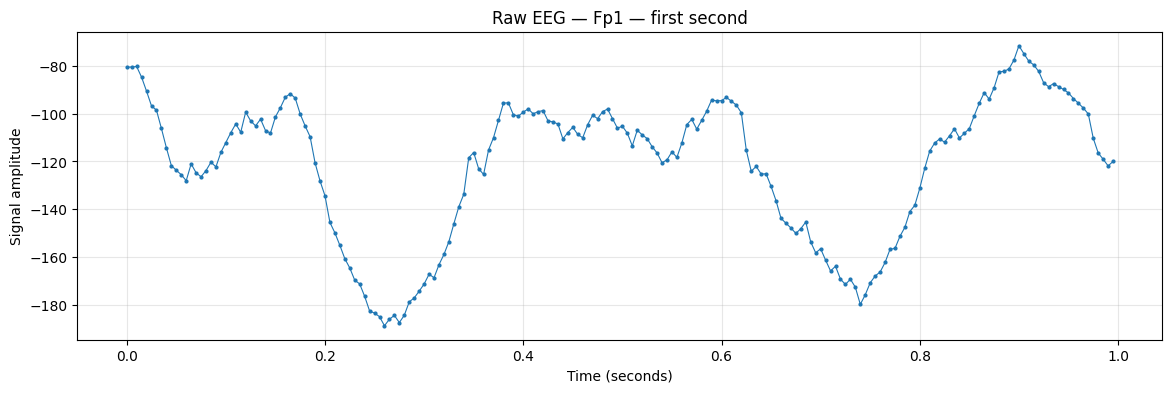

Số sample được vẽ: 200


In [7]:
import numpy as np
import matplotlib.pyplot as plt

time = np.arange(len(segment)) / fs + offset_seconds

mask = (
    (time >= offset_seconds)
    & (time < offset_seconds + 1)
)

plt.figure(figsize=(14, 4))
plt.plot(
    time[mask],
    segment.loc[mask, "Fp1"],
    marker="o",
    markersize=2,
    linewidth=0.8
)

plt.xlabel("Time (seconds)")
plt.ylabel("Signal amplitude")
plt.title("Raw EEG — Fp1 — first second")
plt.grid(alpha=0.3)
plt.show()

print("Số sample được vẽ:", mask.sum())

In [8]:
montage_pairs = {
    "Fp1-F7": ("Fp1", "F7"),
    "F7-T3": ("F7", "T3"),
    "T3-T5": ("T3", "T5"),
    "T5-O1": ("T5", "O1"),

    "Fp2-F8": ("Fp2", "F8"),
    "F8-T4": ("F8", "T4"),
    "T4-T6": ("T4", "T6"),
    "T6-O2": ("T6", "O2"),

    "Fp1-F3": ("Fp1", "F3"),
    "F3-C3": ("F3", "C3"),
    "C3-P3": ("C3", "P3"),
    "P3-O1": ("P3", "O1"),

    "Fp2-F4": ("Fp2", "F4"),
    "F4-C4": ("F4", "C4"),
    "C4-P4": ("C4", "P4"),
    "P4-O2": ("P4", "O2"),
}

required_electrodes = {
    electrode
    for pair in montage_pairs.values()
    for electrode in pair
}

missing = required_electrodes - set(segment.columns)

print("Số kênh sẽ tạo:", len(montage_pairs))
print("Điện cực bị thiếu:", sorted(missing))

assert not missing, f"Thiếu điện cực: {sorted(missing)}"

Số kênh sẽ tạo: 16
Điện cực bị thiếu: []


In [9]:
bipolar = pd.DataFrame(index=segment.index)

for name, (electrode_a, electrode_b) in montage_pairs.items():
    bipolar[name] = segment[electrode_a] - segment[electrode_b]

assert bipolar.shape == (segment_length, 16)
assert np.isfinite(bipolar.to_numpy()).all(), \
    "Montage còn NaN hoặc infinity; cần xử lý trước khi tiếp tục"

print("Kích thước bipolar:", bipolar.shape)
display(bipolar.head())

Kích thước bipolar: (10000, 16)


,Fp1-F7,F7-T3,T3-T5,T5-O1,Fp2-F8,F8-T4,T4-T6,T6-O2,Fp1-F3,F3-C3,C3-P3,P3-O1,Fp2-F4,F4-C4,C4-P4,P4-O2
0,39.810005,-31.709999,13.129997,2.739998,17.959999,2.410004,23.370003,-15.280006,-9.979996,9.570000,28.639999,-4.260002,10.840004,23.290001,-4.010002,-1.660004
1,40.320000,-29.949997,13.440002,-4.529999,12.970001,-8.180000,26.209999,-13.440002,-10.119995,11.430000,25.909996,-7.939995,0.489998,30.620003,-11.750000,-1.800003
2,37.290001,-30.010002,12.099998,-2.769997,-3.570000,0.149994,27.860001,-18.089996,-4.339996,6.180000,23.959999,-9.190002,5.149994,22.940002,-14.180000,-7.559998
3,36.700005,-26.660004,10.620003,-5.090004,-1.770004,-0.279999,31.760002,-19.050003,-9.370003,12.140007,21.489998,-8.690002,1.989998,24.549995,-13.879997,-2.000000
4,39.390007,-27.100006,15.739998,-17.500000,2.199997,-8.769997,26.119995,-14.599998,-9.779999,12.209999,20.870003,-12.770004,-6.370003,26.709999,-15.839996,0.449997


In [10]:
fp1_value = segment["Fp1"].iloc[0]
f7_value = segment["F7"].iloc[0]
bipolar_value = bipolar["Fp1-F7"].iloc[0]

print("Fp1:", fp1_value)
print("F7:", f7_value)
print("Fp1 - F7:", fp1_value - f7_value)
print("Giá trị trong bipolar:", bipolar_value)

assert np.isclose(bipolar_value, fp1_value - f7_value)

Fp1: -80.52
F7: -120.33
Fp1 - F7: 39.810005
Giá trị trong bipolar: 39.810005


In [11]:
from scipy.signal import butter, sosfiltfilt

low_cut = 0.5
high_cut = 40.0
filter_order = 4

assert 0 < low_cut < high_cut < fs / 2

sos = butter(
    N=filter_order,
    Wn=[low_cut, high_cut],
    btype="bandpass",
    fs=fs,
    output="sos"
)

print("Dải lọc:", low_cut, "-", high_cut, "Hz")
print("Shape hệ số SOS:", sos.shape)

Dải lọc: 0.5 - 40.0 Hz
Shape hệ số SOS: (4, 6)


In [12]:
filtered_array = sosfiltfilt(
    sos,
    bipolar.to_numpy(dtype=np.float64),
    axis=0
)

filtered_eeg = pd.DataFrame(
    filtered_array,
    index=bipolar.index,
    columns=bipolar.columns
)

assert filtered_eeg.shape == bipolar.shape
assert np.isfinite(filtered_array).all()

print("Shape sau lọc:", filtered_eeg.shape)

Shape sau lọc: (10000, 16)


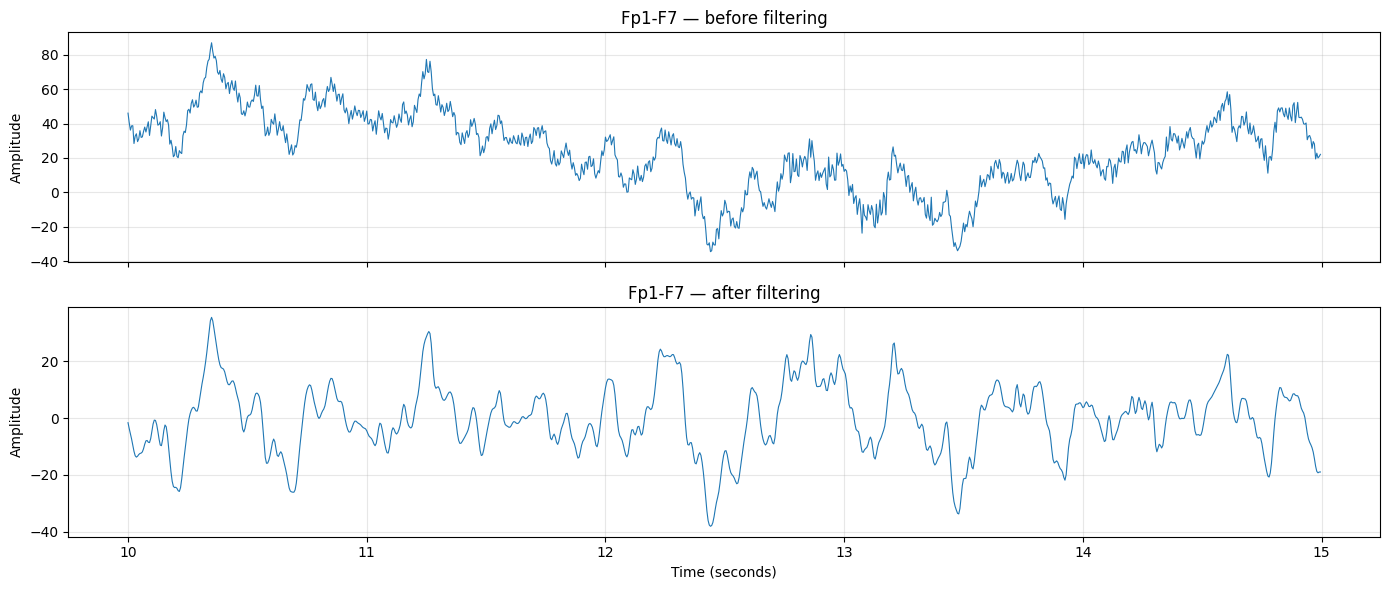

In [13]:
channel = "Fp1-F7"

# Xem giây 10–15 để tránh quan sát ngay sát biên segment
mask = (
    (time >= offset_seconds + 10)
    & (time < offset_seconds + 15)
)

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

axes[0].plot(time[mask], bipolar.loc[mask, channel], linewidth=0.8)
axes[0].set_title(f"{channel} — before filtering")

axes[1].plot(time[mask], filtered_eeg.loc[mask, channel], linewidth=0.8)
axes[1].set_title(f"{channel} — after filtering")

for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.grid(alpha=0.3)

axes[1].set_xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

In [14]:
from scipy.signal import welch

channel = "Fp1-F7"

frequencies, psd_before = welch(
    bipolar[channel].to_numpy(),
    fs=fs,
    nperseg=2000
)

_, psd_after = welch(
    filtered_eeg[channel].to_numpy(),
    fs=fs,
    nperseg=2000
)

print("Khoảng tần số:", frequencies[0], "đến", frequencies[-1], "Hz")
print("Khoảng cách giữa các điểm tần số:",
      frequencies[1] - frequencies[0], "Hz")

Khoảng tần số: 0.0 đến 100.0 Hz
Khoảng cách giữa các điểm tần số: 0.1 Hz


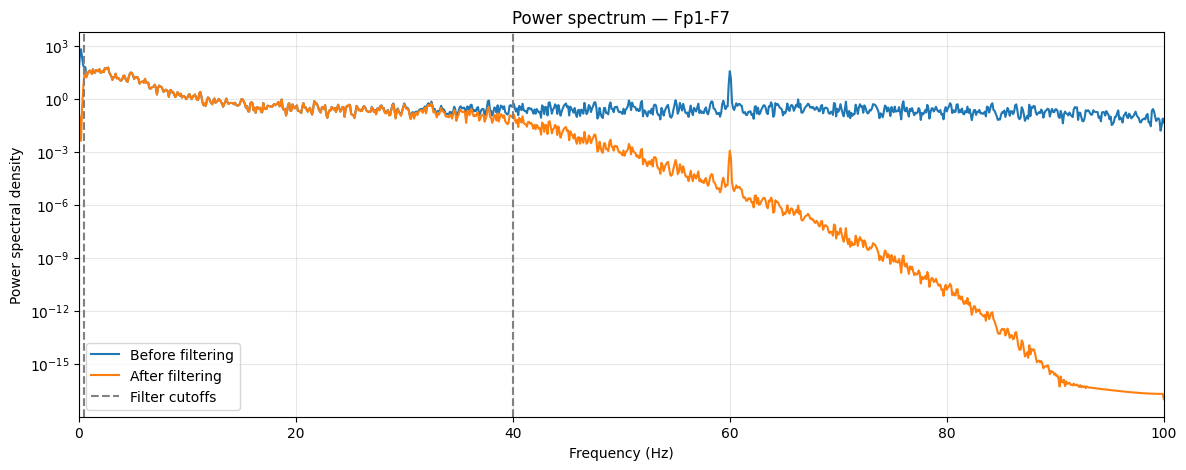

In [15]:
plt.figure(figsize=(14, 5))

plt.semilogy(frequencies, psd_before, label="Before filtering")
plt.semilogy(frequencies, psd_after, label="After filtering")

plt.axvline(low_cut, color="gray", linestyle="--", label="Filter cutoffs")
plt.axvline(high_cut, color="gray", linestyle="--")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power spectral density")
plt.title(f"Power spectrum — {channel}")
plt.xlim(0, fs / 2)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [16]:
channel_stats = pd.DataFrame({
    "mean": filtered_eeg.mean(axis=0),
    "std": filtered_eeg.std(axis=0, ddof=0),
    "rms": np.sqrt((filtered_eeg ** 2).mean(axis=0))
})

print("Shape bảng đặc trưng:", channel_stats.shape)
display(channel_stats)

Shape bảng đặc trưng: (16, 3)


,mean,std,rms
Fp1-F7,-0.046583,12.943809,12.943892
F7-T3,-0.006400,9.491845,9.491847
T3-T5,-0.062210,10.046598,10.046790
T5-O1,-0.026554,11.884806,11.884836
Fp2-F8,-0.142944,10.004511,10.005532
F8-T4,-0.090178,12.543390,12.543714
T4-T6,0.060342,15.758474,15.758589
T6-O2,0.003200,11.599786,11.599786
Fp1-F3,0.021823,11.564700,11.564721
F3-C3,-0.074868,9.355677,9.355976


In [17]:
feature_dict = {}

for channel_name in channel_stats.index:
    for feature_name in channel_stats.columns:
        key = f"{channel_name}__{feature_name}"
        feature_dict[key] = channel_stats.loc[channel_name, feature_name]

feature_vector = pd.Series(feature_dict, name="segment_features")

print("Số đặc trưng:", len(feature_vector))
display(feature_vector.head(9))

Số đặc trưng: 48


Fp1-F7__mean    -0.046583
Fp1-F7__std     12.943809
Fp1-F7__rms     12.943892
F7-T3__mean     -0.006400
F7-T3__std       9.491845
F7-T3__rms       9.491847
T3-T5__mean     -0.062210
T3-T5__std      10.046598
T3-T5__rms      10.046790
Name: segment_features, dtype: float64

In [18]:
frequency_bands = {
    "delta": (0.5, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta": (13, 30)
}

freqs, psd_all = welch(
    filtered_eeg.to_numpy(),
    fs=fs,
    nperseg=2000,
    axis=0
)

print("Shape phổ công suất:", psd_all.shape)

Shape phổ công suất: (1001, 16)


In [19]:
frequency_step = freqs[1] - freqs[0]

for band_name, (low, high) in frequency_bands.items():
    band_mask = (freqs >= low) & (freqs < high)

    band_power = psd_all[band_mask].sum(axis=0) * frequency_step

    for channel_index, channel_name in enumerate(filtered_eeg.columns):
        key = f"{channel_name}__{band_name}_power"
        feature_dict[key] = band_power[channel_index]

feature_vector = pd.Series(feature_dict, name="segment_features")

assert np.isfinite(feature_vector.to_numpy()).all()

print("Tổng số đặc trưng:", len(feature_vector))
display(feature_vector.tail(8))

Tổng số đặc trưng: 112


Fp1-F3__beta_power     5.565368
F3-C3__beta_power     13.899797
C3-P3__beta_power     13.986335
P3-O1__beta_power      3.245564
Fp2-F4__beta_power    10.945739
F4-C4__beta_power     42.253871
C4-P4__beta_power     54.266344
P4-O2__beta_power     18.384348
Name: segment_features, dtype: float64

In [20]:
from scipy.stats import skew, kurtosis

signal_array = filtered_eeg.to_numpy(dtype=np.float64)

extra_stats = pd.DataFrame(
    {
        "min": signal_array.min(axis=0),
        "max": signal_array.max(axis=0),
        "median": np.median(signal_array, axis=0),
        "variance": signal_array.var(axis=0, ddof=0),
        "skewness": skew(signal_array, axis=0, bias=False),
        "kurtosis": kurtosis(
            signal_array, axis=0, fisher=True, bias=False
        )
    },
    index=filtered_eeg.columns
)

# Với kênh hằng, skewness/kurtosis không xác định.
# Quy ước hai đặc trưng này bằng 0 cho kênh đó.
constant_channels = np.ptp(signal_array, axis=0) == 0
extra_stats.loc[
    constant_channels, ["skewness", "kurtosis"]
] = 0.0

assert np.isfinite(extra_stats.to_numpy()).all()

display(extra_stats.head())

,min,max,median,variance,skewness,kurtosis
Fp1-F7,-44.355719,44.065495,-0.053179,167.542182,-0.058434,-0.021057
F7-T3,-34.129601,38.489074,0.026461,90.095127,0.062425,0.055685
T3-T5,-39.859753,41.965253,0.142896,100.934127,-0.071053,0.172955
T5-O1,-56.573525,42.478093,-0.250131,141.248624,0.026409,0.159715
Fp2-F8,-46.638496,44.665811,0.220830,100.090236,-0.192540,0.498968


In [21]:
for channel_name in extra_stats.index:
    for feature_name in extra_stats.columns:
        key = f"{channel_name}__{feature_name}"
        feature_dict[key] = extra_stats.loc[
            channel_name, feature_name
        ]

feature_vector = pd.Series(
    feature_dict,
    name=f"label_{row['label_id']}",
    dtype=np.float64
)

assert len(feature_vector) == 16 * 13
assert feature_vector.index.is_unique
assert np.isfinite(feature_vector.to_numpy()).all()

print("Tổng số đặc trưng:", len(feature_vector))
print("Có giá trị thiếu:", feature_vector.isna().any())

Tổng số đặc trưng: 208
Có giá trị thiếu: False


In [22]:
def preprocess_segment(annotation, recording=None):
    eeg_id = int(annotation["eeg_id"])
    offset = float(annotation["eeg_label_offset_seconds"])

    if recording is None:
        recording = pd.read_parquet(
            EEG_DIR / f"{eeg_id}.parquet"
        )

    start = int(round(offset * fs))
    end = start + segment_length

    if not (0 <= start < end <= len(recording)):
        raise ValueError(f"Segment vượt recording: eeg_id={eeg_id}")

    required = sorted(required_electrodes)

    missing = set(required) - set(recording.columns)
    if missing:
        raise ValueError(f"Thiếu điện cực: {sorted(missing)}")

    raw = recording.iloc[start:end][required].copy()
    raw = raw.replace([np.inf, -np.inf], np.nan)

    # Quy tắc ban đầu: loại segment nếu một điện cực
    # thiếu trên 10% sample.
    missing_ratio = raw.isna().mean()
    bad_channels = missing_ratio[missing_ratio > 0.10]

    if not bad_channels.empty:
        raise ValueError(
            f"Điện cực thiếu trên 10% dữ liệu: {bad_channels.index.tolist()}"
        )

    # Nội suy theo thời gian; điền khoảng thiếu ở hai đầu.
    raw = raw.interpolate(
        method="linear",
        axis=0,
        limit_direction="both"
    )

    bipolar_segment = pd.DataFrame({
        name: raw[a] - raw[b]
        for name, (a, b) in montage_pairs.items()
    })

    filtered = sosfiltfilt(
        sos,
        bipolar_segment.to_numpy(dtype=np.float64),
        axis=0
    )

    if not np.isfinite(filtered).all():
        raise ValueError("Tín hiệu sau xử lý có NaN hoặc infinity")

    return pd.DataFrame(
        filtered,
        index=raw.index,
        columns=bipolar_segment.columns
    )

In [23]:
def extract_features(processed_eeg):
    x = processed_eeg.to_numpy(dtype=np.float64)

    stats = {
        "mean": x.mean(axis=0),
        "std": x.std(axis=0, ddof=0),
        "rms": np.sqrt((x ** 2).mean(axis=0)),
        "min": x.min(axis=0),
        "max": x.max(axis=0),
        "median": np.median(x, axis=0),
        "variance": x.var(axis=0, ddof=0)
    }

    # Chỉ tính skewness/kurtosis cho kênh không hằng.
    nonconstant = np.ptp(x, axis=0) > 0
    skew_values = np.zeros(x.shape[1])
    kurtosis_values = np.zeros(x.shape[1])

    skew_values[nonconstant] = skew(
        x[:, nonconstant], axis=0, bias=False
    )
    kurtosis_values[nonconstant] = kurtosis(
        x[:, nonconstant], axis=0, fisher=True, bias=False
    )

    stats["skewness"] = skew_values
    stats["kurtosis"] = kurtosis_values

    frequencies, power = welch(
        x, fs=fs, nperseg=2000, axis=0
    )
    frequency_step = frequencies[1] - frequencies[0]

    for band, (low, high) in frequency_bands.items():
        mask = (frequencies >= low) & (frequencies < high)
        stats[f"{band}_power"] = (
            power[mask].sum(axis=0) * frequency_step
        )

    features = {
        f"{channel}__{feature}": values[channel_index]
        for channel_index, channel in enumerate(processed_eeg.columns)
        for feature, values in stats.items()
    }

    result = pd.Series(features, dtype=np.float64)

    assert len(result) == 208
    assert np.isfinite(result.to_numpy()).all()

    return result

In [24]:
processed_test = preprocess_segment(row)
features_test = extract_features(processed_test)

print("Shape EEG sau xử lý:", processed_test.shape)
print("Số đặc trưng:", len(features_test))

# Căn đúng thứ tự tên đặc trưng trước khi so sánh.
features_manual = feature_vector.reindex(features_test.index)

assert features_manual.notna().all(), \
    "Tên đặc trưng giữa hai cách tính không khớp"

same_signal = np.allclose(
    processed_test.to_numpy(),
    filtered_eeg.to_numpy()
)

same_features = np.allclose(
    features_test.to_numpy(),
    features_manual.to_numpy()
)

print("Tín hiệu khớp cách làm trước:", same_signal)
print("Đặc trưng khớp cách làm trước:", same_features)

assert same_signal and same_features

Shape EEG sau xử lý: (10000, 16)
Số đặc trưng: 208
Tín hiệu khớp cách làm trước: True
Đặc trưng khớp cách làm trước: True


In [25]:
row_test = train[
    train["eeg_label_offset_seconds"] > 0
].iloc[0]

processed_offset = preprocess_segment(row_test)
features_offset = extract_features(processed_offset)

print("eeg_id:", int(row_test["eeg_id"]))
print("Offset:", row_test["eeg_label_offset_seconds"], "giây")
print("Shape sau xử lý:", processed_offset.shape)
print("Số đặc trưng:", len(features_offset))

eeg_id: 1628180742
Offset: 6.0 giây
Shape sau xử lý: (10000, 16)
Số đặc trưng: 208


In [26]:
class_order = ["Seizure", "LPD", "GPD", "LRDA", "GRDA", "Other"]

vote_columns = [
    "seizure_vote", "lpd_vote", "gpd_vote",
    "lrda_vote", "grda_vote", "other_vote"
]

label_mapping = {
    name.lower(): index
    for index, name in enumerate(class_order)
}

clean_labels = train["expert_consensus"].str.strip().str.lower()
train["hard_label"] = clean_labels.map(label_mapping)

votes_array = train[vote_columns].to_numpy(dtype=np.float64)
vote_totals = votes_array.sum(axis=1)

assert train["hard_label"].notna().all()
assert np.isfinite(votes_array).all()
assert (votes_array >= 0).all()
assert (vote_totals > 0).all()

train["hard_label"] = train["hard_label"].astype(int)
soft_targets = votes_array / vote_totals[:, None]

assert np.allclose(soft_targets.sum(axis=1), 1.0)

print("Shape soft targets:", soft_targets.shape)
print("Hard label bị thiếu:", train["hard_label"].isna().sum())

Shape soft targets: (106800, 6)
Hard label bị thiếu: 0


In [27]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train["fold"] = -1

for fold_id, (_, val_positions) in enumerate(
    splitter.split(
        X=np.zeros(len(train)),
        y=train["hard_label"],
        groups=train["patient_id"]
    )
):
    train.iloc[
        val_positions, train.columns.get_loc("fold")
    ] = fold_id

# Thử fold 0 trước.
train_mask = train["fold"] != 0
val_mask = train["fold"] == 0

train_patients = set(train.loc[train_mask, "patient_id"])
val_patients = set(train.loc[val_mask, "patient_id"])

overlap = train_patients & val_patients

assert train["fold"].between(0, 4).all()
assert train.groupby("patient_id")["fold"].nunique().eq(1).all()
assert not overlap

print("Số annotation mỗi fold:")
print(train["fold"].value_counts().sort_index())
print("Số bệnh nhân trùng train/validation:", len(overlap))

Số annotation mỗi fold:
fold
0    17085
1    25502
2    21174
3    22141
4    20898
Name: count, dtype: int64
Số bệnh nhân trùng train/validation: 0


In [28]:
def sample_per_class(table, n_per_class):
    return pd.concat([
        table[table["hard_label"] == class_id].sample(
            n=min(n_per_class, (table["hard_label"] == class_id).sum()),
            random_state=42
        )
        for class_id in range(6)
    ]).sort_index()

train_demo = sample_per_class(train.loc[train_mask], 50)
val_demo = sample_per_class(train.loc[val_mask], 20)

assert set(train_demo["patient_id"]).isdisjoint(
    set(val_demo["patient_id"])
)

print("Annotation train thử:", len(train_demo))
print("Annotation validation thử:", len(val_demo))

Annotation train thử: 300
Annotation validation thử: 120


In [29]:
from tqdm.auto import tqdm

def build_feature_table(annotations):
    feature_rows = []
    kept_indices = []
    failures = []

    for index, annotation in tqdm(
        annotations.iterrows(),
        total=len(annotations)
    ):
        try:
            processed = preprocess_segment(annotation)
            features = extract_features(processed)
        except ValueError as error:
            failures.append({
                "row_index": index,
                "label_id": annotation["label_id"],
                "reason": str(error)
            })
            continue

        feature_rows.append(features)
        kept_indices.append(index)

    if not feature_rows:
        raise ValueError("Không có annotation nào xử lý thành công")

    X = pd.DataFrame(feature_rows, index=kept_indices)
    metadata = annotations.loc[kept_indices].copy()
    errors = pd.DataFrame(
        failures,
        columns=["row_index", "label_id", "reason"]
    )

    assert X.index.equals(metadata.index)
    assert X.shape[1] == 208
    assert np.isfinite(X.to_numpy()).all()

    return X, metadata, errors


X_train_demo, meta_train_demo, errors_train = build_feature_table(
    train_demo
)

X_val_demo, meta_val_demo, errors_val = build_feature_table(
    val_demo
)

assert X_train_demo.columns.equals(X_val_demo.columns)

print("Shape X train:", X_train_demo.shape)
print("Shape X validation:", X_val_demo.shape)
print("Annotation train bị loại:", len(errors_train))
print("Annotation validation bị loại:", len(errors_val))

display(errors_train.head())
display(errors_val.head())

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/120 [00:00<?, ?it/s]

Shape X train: (299, 208)
Shape X validation: (120, 208)
Annotation train bị loại: 1
Annotation validation bị loại: 0


,row_index,label_id,reason
0,15952,3781931820,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."


,row_index,label_id,reason


In [30]:
from sklearn.ensemble import RandomForestClassifier

y_train_demo = meta_train_demo["hard_label"].to_numpy()
y_val_demo = meta_val_demo["hard_label"].to_numpy()

rf_demo = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_demo.fit(X_train_demo, y_train_demo)

print("Đã train Random Forest.")
print("Các class model đã học:", rf_demo.classes_)

Đã train Random Forest.
Các class model đã học: [0 1 2 3 4 5]


In [31]:
from sklearn.metrics import accuracy_score, f1_score
from scipy.special import rel_entr

predicted_classes = rf_demo.predict(X_val_demo)
raw_probabilities = rf_demo.predict_proba(X_val_demo)

# Đặt xác suất vào đúng thứ tự sáu class của dự án.
probabilities = np.zeros((len(X_val_demo), 6))
probabilities[:, rf_demo.classes_.astype(int)] = raw_probabilities

# Tránh log(0), rồi chuẩn hóa lại tổng mỗi hàng về 1.
probabilities = np.clip(probabilities, 1e-7, 1.0)
probabilities /= probabilities.sum(axis=1, keepdims=True)

# Tạo soft target trực tiếp từ metadata validation được giữ lại.
val_votes = meta_val_demo[vote_columns].to_numpy(dtype=np.float64)
val_soft_targets = val_votes / val_votes.sum(axis=1, keepdims=True)

accuracy = accuracy_score(y_val_demo, predicted_classes)
macro_f1 = f1_score(
    y_val_demo,
    predicted_classes,
    labels=np.arange(6),
    average="macro",
    zero_division=0
)

kl = rel_entr(val_soft_targets, probabilities).sum(axis=1).mean()

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"KL Divergence: {kl:.4f}")

Accuracy: 0.3917
Macro F1: 0.3864
KL Divergence: 1.1109


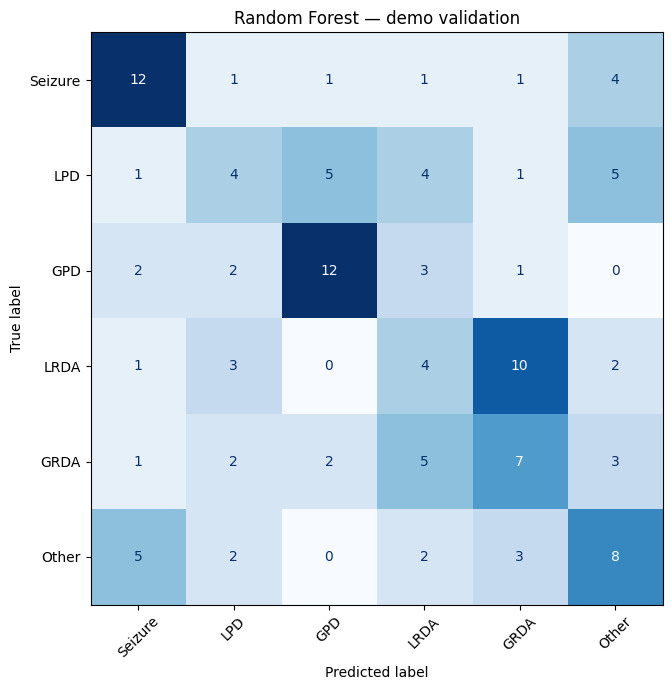

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_val_demo,
    predicted_classes,
    labels=np.arange(6)
)

fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_order
).plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("Random Forest — demo validation")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val_demo,
    predicted_classes,
    labels=np.arange(6),
    target_names=class_order,
    digits=3,
    zero_division=0
))

              precision    recall  f1-score   support

     Seizure      0.545     0.600     0.571        20
         LPD      0.286     0.200     0.235        20
         GPD      0.600     0.600     0.600        20
        LRDA      0.211     0.200     0.205        20
        GRDA      0.304     0.350     0.326        20
       Other      0.364     0.400     0.381        20

    accuracy                          0.392       120
   macro avg      0.385     0.392     0.386       120
weighted avg      0.385     0.392     0.386       120



In [34]:
def build_feature_table_grouped(annotations):
    feature_rows = []
    kept_indices = []
    failures = []

    groups = annotations.groupby("eeg_id", sort=True)

    for eeg_id, recording_rows in tqdm(
        groups,
        total=groups.ngroups,
        desc="Processing recordings"
    ):
        recording = pd.read_parquet(
            EEG_DIR / f"{int(eeg_id)}.parquet"
        )

        for index, annotation in recording_rows.iterrows():
            try:
                processed = preprocess_segment(
                    annotation, recording=recording
                )
                features = extract_features(processed)
            except ValueError as error:
                failures.append({
                    "row_index": index,
                    "label_id": annotation["label_id"],
                    "reason": str(error)
                })
                continue

            feature_rows.append(features)
            kept_indices.append(index)

    if not feature_rows:
        raise ValueError("Không có annotation nào xử lý thành công")

    X = pd.DataFrame(
        feature_rows, index=kept_indices
    ).sort_index()

    metadata = annotations.loc[X.index].copy()

    errors = pd.DataFrame(
        failures,
        columns=["row_index", "label_id", "reason"]
    )

    assert X.index.equals(metadata.index)
    assert X.shape[1] == 208
    assert np.isfinite(X.to_numpy()).all()

    return X, metadata, errors

In [35]:
X_check, meta_check, errors_check = build_feature_table_grouped(
    train_demo
)

X_reference = X_train_demo.reindex(
    index=X_check.index,
    columns=X_check.columns
)

assert X_check.index.equals(X_train_demo.sort_index().index)
assert np.allclose(
    X_check.to_numpy(),
    X_reference.to_numpy()
)
assert set(errors_check["row_index"]) == set(errors_train["row_index"])

print("Kết quả khớp bản cũ.")
print("Shape:", X_check.shape)
print("Số annotation bị loại:", len(errors_check))

Processing recordings:   0%|          | 0/272 [00:00<?, ?it/s]

Kết quả khớp bản cũ.
Shape: (299, 208)
Số annotation bị loại: 1


In [36]:
train_large = sample_per_class(
    train.loc[train_mask],
    n_per_class=500
)

# Dùng toàn bộ fold 0 để giữ phân bố validation thực tế.
val_full = train.loc[val_mask].copy()

assert set(train_large["patient_id"]).isdisjoint(
    set(val_full["patient_id"])
)

print("Số annotation train:", len(train_large))
print("Số annotation validation:", len(val_full))
print("Số recording train:", train_large["eeg_id"].nunique())
print("Số recording validation:", val_full["eeg_id"].nunique())

Số annotation train: 3000
Số annotation validation: 17085
Số recording train: 2138
Số recording validation: 2795


In [37]:
X_train_large, meta_train_large, errors_train_large = (
    build_feature_table_grouped(train_large)
)

X_val_full, meta_val_full, errors_val_full = (
    build_feature_table_grouped(val_full)
)

assert X_train_large.columns.equals(X_val_full.columns)

print("Shape train:", X_train_large.shape)
print("Shape validation:", X_val_full.shape)
print("Train bị loại:", len(errors_train_large))
print("Validation bị loại:", len(errors_val_full))

display(errors_train_large.head())
display(errors_val_full.head())

Processing recordings:   0%|          | 0/2138 [00:00<?, ?it/s]

Processing recordings:   0%|          | 0/2795 [00:00<?, ?it/s]

Shape train: (2995, 208)
Shape validation: (17059, 208)
Train bị loại: 5
Validation bị loại: 26


,row_index,label_id,reason
0,15952,3781931820,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."
1,49797,2507465731,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."
2,90621,1796036494,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."
3,11572,478179165,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."
4,65279,2597702684,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."


,row_index,label_id,reason
0,66816,3249053595,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."
1,66817,2917720091,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."
2,71610,791418094,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."
3,41596,126012346,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."
4,82191,31335689,"Điện cực thiếu trên 10% dữ liệu: ['C3', 'C4', ..."


In [38]:
import json

OUTPUT_DIR = Path("/kaggle/working/rf_features_v1")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

tables = {
    "X_train": X_train_large,
    "X_validation": X_val_full,
    "metadata_train": meta_train_large,
    "metadata_validation": meta_val_full,
    "errors_train": errors_train_large,
    "errors_validation": errors_val_full
}

for name, table in tables.items():
    table.to_parquet(OUTPUT_DIR / f"{name}.parquet")

# Lưu toàn bộ cách chia fold để các model sau dùng chung.
train[["label_id", "eeg_id", "patient_id", "fold"]].to_parquet(
    OUTPUT_DIR / "fold_assignments.parquet"
)

config = {
    "fs": fs,
    "segment_seconds": segment_seconds,
    "filter_low": low_cut,
    "filter_high": high_cut,
    "filter_order": filter_order,
    "missing_ratio_threshold": 0.10,
    "welch_nperseg": 2000,
    "frequency_bands": frequency_bands,
    "montage_pairs": montage_pairs,
    "class_order": class_order,
    "validation_fold": 0,
    "train_samples_per_class": 500,
    "random_state": 42,
    "feature_columns": X_train_large.columns.tolist()
}

with open(OUTPUT_DIR / "config.json", "w") as file:
    json.dump(config, file, indent=2)

print("Đã lưu tại:", OUTPUT_DIR)

Đã lưu tại: /kaggle/working/rf_features_v1


In [39]:
import joblib

rf_large = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_large.fit(
    X_train_large,
    meta_train_large["hard_label"].to_numpy()
)

joblib.dump(rf_large, OUTPUT_DIR / "random_forest.joblib")

print("Đã train và lưu Random Forest.")

Đã train và lưu Random Forest.


In [40]:
y_val_full = meta_val_full["hard_label"].to_numpy()
pred_full = rf_large.predict(X_val_full)

proba_full = np.zeros((len(X_val_full), 6))
proba_full[:, rf_large.classes_.astype(int)] = (
    rf_large.predict_proba(X_val_full)
)

proba_full = np.clip(proba_full, 1e-7, 1.0)
proba_full /= proba_full.sum(axis=1, keepdims=True)

votes_full = meta_val_full[vote_columns].to_numpy(dtype=float)
targets_full = votes_full / votes_full.sum(axis=1, keepdims=True)

metrics_full = {
    "accuracy": accuracy_score(y_val_full, pred_full),
    "macro_f1": f1_score(
        y_val_full, pred_full,
        labels=np.arange(6),
        average="macro",
        zero_division=0
    ),
    "kl": rel_entr(targets_full, proba_full).sum(axis=1).mean()
}

for name, value in metrics_full.items():
    print(f"{name}: {value:.4f}")

pd.DataFrame([metrics_full]).to_csv(
    OUTPUT_DIR / "metrics.csv", index=False
)

prediction_table = meta_val_full[
    ["label_id", "eeg_id", "patient_id", "hard_label"]
].copy()

prediction_table["predicted_class"] = pred_full

for class_index, class_name in enumerate(class_order):
    prediction_table[f"prob_{class_name}"] = proba_full[:, class_index]

prediction_table.to_parquet(
    OUTPUT_DIR / "validation_predictions.parquet"
)

accuracy: 0.4371
macro_f1: 0.4198
kl: 1.0789


In [41]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

svm_model.fit(
    X_train_large,
    meta_train_large["hard_label"].to_numpy()
)

joblib.dump(svm_model, OUTPUT_DIR / "svm.joblib")

print("Đã train và lưu SVM.")

Đã train và lưu SVM.


In [42]:
svm_pred = svm_model.predict(X_val_full)

svm_proba = np.zeros((len(X_val_full), 6))
svm_proba[:, svm_model.classes_.astype(int)] = (
    svm_model.predict_proba(X_val_full)
)

svm_proba = np.clip(svm_proba, 1e-7, 1.0)
svm_proba /= svm_proba.sum(axis=1, keepdims=True)

svm_metrics = {
    "accuracy": accuracy_score(y_val_full, svm_pred),
    "macro_f1": f1_score(
        y_val_full, svm_pred,
        labels=np.arange(6),
        average="macro",
        zero_division=0
    ),
    "kl": rel_entr(targets_full, svm_proba).sum(axis=1).mean()
}

comparison = pd.DataFrame(
    [metrics_full, svm_metrics],
    index=["Random Forest", "SVM"]
)

display(comparison)

comparison.to_csv(OUTPUT_DIR / "rf_svm_comparison.csv")

,accuracy,macro_f1,kl
Random Forest,0.437130,0.419773,1.078913
SVM,0.305938,0.185011,1.328050


In [43]:
print(classification_report(
    y_val_full,
    svm_pred,
    labels=np.arange(6),
    target_names=class_order,
    digits=3,
    zero_division=0
))

prediction_counts = pd.Series(
    svm_pred
).value_counts().reindex(range(6), fill_value=0)

display(pd.DataFrame({
    "class": class_order,
    "actual_count": np.bincount(y_val_full, minlength=6),
    "predicted_count": prediction_counts.to_numpy()
}))

              precision    recall  f1-score   support

     Seizure      0.569     0.287     0.382      3997
         LPD      0.042     0.010     0.017      1168
         GPD      0.299     0.080     0.126      2050
        LRDA      0.265     0.936     0.413      3787
        GRDA      0.096     0.006     0.011      2604
       Other      0.486     0.096     0.161      3453

    accuracy                          0.306     17059
   macro avg      0.293     0.236     0.185     17059
weighted avg      0.344     0.306     0.232     17059



,class,actual_count,predicted_count
0,Seizure,3997,2018
1,LPD,1168,284
2,GPD,2050,548
3,LRDA,3787,13367
4,GRDA,2604,157
5,Other,3453,685


In [44]:
from sklearn.preprocessing import RobustScaler

svm_robust = Pipeline([
    ("scaler", RobustScaler()),
    ("svm", SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

svm_robust.fit(
    X_train_large,
    meta_train_large["hard_label"].to_numpy()
)

robust_pred = svm_robust.predict(X_val_full)

print(classification_report(
    y_val_full,
    robust_pred,
    labels=np.arange(6),
    target_names=class_order,
    digits=3,
    zero_division=0
))

print(
    "Tỷ lệ dự đoán LRDA:",
    f"{(robust_pred == 3).mean() * 100:.2f}%"
)

              precision    recall  f1-score   support

     Seizure      0.593     0.014     0.026      3997
         LPD      0.000     0.000     0.000      1168
         GPD      0.000     0.000     0.000      2050
        LRDA      0.000     0.000     0.000      3787
        GRDA      0.154     0.995     0.267      2604
       Other      0.473     0.018     0.034      3453

    accuracy                          0.159     17059
   macro avg      0.203     0.171     0.055     17059
weighted avg      0.258     0.159     0.054     17059

Tỷ lệ dự đoán LRDA: 0.15%


In [45]:
for name, model in [
    ("StandardScaler", svm_model),
    ("RobustScaler", svm_robust)
]:
    scaled_train = model.named_steps["scaler"].transform(
        X_train_large
    )

    print(f"\n{name}")
    print("Gamma thực tế:", model.named_steps["svm"]._gamma)
    print(
        "Phân vị |feature| [50%, 95%, 99%, max]:",
        np.quantile(np.abs(scaled_train), [0.50, 0.95, 0.99, 1.0])
    )


StandardScaler
Gamma thực tế: 0.004807692307692309
Phân vị |feature| [50%, 95%, 99%, max]: [4.93707696e-02 1.94914182e-01 9.40391851e-01 5.35103669e+01]

RobustScaler
Gamma thực tế: 3.427926763825684e-11
Phân vị |feature| [50%, 95%, 99%, max]: [3.64377177e-01 5.87774018e+00 6.59695844e+01 2.66094095e+06]


In [46]:
for name, model in [
    ("SVM Standard", svm_model),
    ("SVM Robust", svm_robust)
]:
    train_predictions = model.predict(X_train_large)
    train_targets = meta_train_large["hard_label"].to_numpy()

    print(f"\n{name}")
    print(
        "Train Accuracy:",
        f"{accuracy_score(train_targets, train_predictions):.4f}"
    )
    print(
        "Train Macro F1:",
        f"{f1_score(train_targets, train_predictions, labels=np.arange(6), average='macro', zero_division=0):.4f}"
    )


SVM Standard
Train Accuracy: 0.3205
Train Macro F1: 0.2795

SVM Robust
Train Accuracy: 0.1763
Train Macro F1: 0.0670


In [47]:
scaled = pd.DataFrame(
    svm_model.named_steps["scaler"].transform(X_train_large),
    index=X_train_large.index,
    columns=X_train_large.columns
)

feature_diagnostics = pd.DataFrame({
    "raw_min": X_train_large.min(),
    "raw_median": X_train_large.median(),
    "raw_max": X_train_large.max(),
    "scaled_abs_max": scaled.abs().max(),
    "scaled_abs_p95": scaled.abs().quantile(0.95)
}).sort_values("scaled_abs_max", ascending=False)

display(feature_diagnostics.head(15))

largest_feature = feature_diagnostics.index[0]
largest_rows = scaled[largest_feature].abs().nlargest(5).index

print("Feature cực đoan nhất:", largest_feature)

display(meta_train_large.loc[
    largest_rows,
    ["label_id", "eeg_id", "patient_id", "expert_consensus"]
])

,raw_min,raw_median,raw_max,scaled_abs_max,scaled_abs_p95
F3-C3__median,-732.701917,0.236560,7.188801e+01,53.510367,0.440214
Fp2-F8__mean,-19.431607,-0.001191,1.785422e+02,53.428672,0.105122
Fp2-F4__mean,-9.351974,-0.001568,1.784387e+02,53.226723,0.114041
P3-O1__theta_power,0.055438,12.775016,3.608069e+07,53.167357,0.029746
T5-O1__theta_power,0.068054,14.099374,2.932753e+07,52.908915,0.031330
P3-O1__alpha_power,0.036657,4.763780,1.655337e+07,52.628628,0.032024
Fp1-F7__median,-1574.401009,0.174113,4.203926e+02,52.601874,0.169086
F3-C3__mean,-181.735337,-0.003298,2.723396e+01,52.188955,0.101476
C4-P4__alpha_power,0.030009,5.856754,2.127575e+07,52.010171,0.029807
T5-O1__alpha_power,0.046462,4.751628,1.520518e+07,51.737516,0.033792


Feature cực đoan nhất: F3-C3__median


,label_id,eeg_id,patient_id,expert_consensus
86362,4085347708,2060506745,40881,Other
10675,451802016,2645143948,57480,Seizure
32407,3407657039,228506855,41951,Seizure
102094,990703360,404977241,33380,Seizure
40552,1507404335,4209971814,1218,LPD


In [48]:
from sklearn.preprocessing import FunctionTransformer

def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))

svm_log = Pipeline([
    ("log", FunctionTransformer(signed_log1p)),
    ("scaler", StandardScaler()),
    ("svm", SVC(
        C=1.0,
        kernel="rbf",
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

svm_log.fit(
    X_train_large,
    meta_train_large["hard_label"].to_numpy()
)

print("Đã train SVM với signed log.")

Đã train SVM với signed log.


In [49]:
log_train_pred = svm_log.predict(X_train_large)
log_val_pred = svm_log.predict(X_val_full)

log_proba = np.zeros((len(X_val_full), 6))
log_proba[:, svm_log.classes_.astype(int)] = (
    svm_log.predict_proba(X_val_full)
)

log_proba = np.clip(log_proba, 1e-7, 1.0)
log_proba /= log_proba.sum(axis=1, keepdims=True)

log_metrics = {
    "accuracy": accuracy_score(y_val_full, log_val_pred),
    "macro_f1": f1_score(
        y_val_full, log_val_pred,
        labels=np.arange(6),
        average="macro",
        zero_division=0
    ),
    "kl": rel_entr(targets_full, log_proba).sum(axis=1).mean()
}

print(
    "Train Accuracy:",
    f"{accuracy_score(meta_train_large['hard_label'], log_train_pred):.4f}"
)

display(pd.DataFrame(
    [metrics_full, svm_metrics, log_metrics],
    index=["Random Forest", "SVM Standard", "SVM Log"]
))

print(classification_report(
    y_val_full,
    log_val_pred,
    labels=np.arange(6),
    target_names=class_order,
    digits=3,
    zero_division=0
))

Train Accuracy: 0.7322


,accuracy,macro_f1,kl
Random Forest,0.437130,0.419773,1.078913
SVM Standard,0.305938,0.185011,1.328050
SVM Log,0.422240,0.402151,1.105817


              precision    recall  f1-score   support

     Seizure      0.585     0.560     0.572      3997
         LPD      0.134     0.180     0.154      1168
         GPD      0.661     0.501     0.570      2050
        LRDA      0.412     0.329     0.366      3787
        GRDA      0.314     0.404     0.353      2604
       Other      0.382     0.414     0.397      3453

    accuracy                          0.422     17059
   macro avg      0.415     0.398     0.402     17059
weighted avg      0.443     0.422     0.429     17059



In [50]:
joblib.dump(
    svm_log,
    OUTPUT_DIR / "svm_signed_log.joblib"
)

comparison_final = pd.DataFrame(
    [metrics_full, svm_metrics, log_metrics],
    index=["Random Forest", "SVM Standard", "SVM Log"]
)

comparison_final.to_csv(
    OUTPUT_DIR / "baseline_comparison.csv"
)

svm_predictions = meta_val_full[
    ["label_id", "eeg_id", "patient_id", "hard_label"]
].copy()

svm_predictions["predicted_class"] = log_val_pred

for i, class_name in enumerate(class_order):
    svm_predictions[f"prob_{class_name}"] = log_proba[:, i]

svm_predictions.to_parquet(
    OUTPUT_DIR / "svm_log_validation_predictions.parquet"
)

print("Đã lưu SVM Log, metrics và dự đoán validation.")

Đã lưu SVM Log, metrics và dự đoán validation.
